# Descriptive Implementation of Bilinear Interpolation for Image

Importing Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Original Image

In [2]:
image = np.array([
    [50, 100],
    [150, 200]
], dtype=float)

print("Original Image:")
print(image)

Original Image:
[[ 50. 100.]
 [150. 200.]]


Output size

In [3]:
# Output image size
new_height = 5
new_width = 5

output = np.zeros((new_height, new_width))

print("Output size:", output.shape)

Output size: (5, 5)


Biliear Interpolation

In [4]:
# Scale factors
height_scale = (image.shape[0] - 1) / (new_height - 1)
width_scale = (image.shape[1] - 1) / (new_width - 1)

for i in range(new_height):
    for j in range(new_width):

        # Find corresponding position in original image
        x = i * height_scale
        y = j * width_scale

        # Find surrounding pixels
        x1 = int(np.floor(x))
        x2 = int(np.ceil(x))

        y1 = int(np.floor(y))
        y2 = int(np.ceil(y))

        # Handle boundary
        if x1 == x2:
            x2 = min(x1 + 1, image.shape[0] - 1)

        if y1 == y2:
            y2 = min(y1 + 1, image.shape[1] - 1)

        # Interpolation weights
        dx = x - x1
        dy = y - y1

        # Four surrounding pixel values
        Q11 = image[x1, y1]
        Q12 = image[x1, y2]
        Q21 = image[x2, y1]
        Q22 = image[x2, y2]

        # Bilinear interpolation formula
        value = (
            Q11 * (1 - dx) * (1 - dy)
            + Q21 * dx * (1 - dy)
            + Q12 * (1 - dx) * dy
            + Q22 * dx * dy
        )

        output[i, j] = value

Displaying values

In [5]:
print("5x5 Image after Bilinear Interpolation:")
print(np.round(output, 2))

5x5 Image after Bilinear Interpolation:
[[ 50.   62.5  75.   87.5 100. ]
 [ 75.   87.5 100.  112.5 125. ]
 [100.  112.5 125.  137.5 150. ]
 [125.  137.5 150.  162.5 175. ]
 [150.  162.5 175.  187.5 200. ]]


Plotting Image

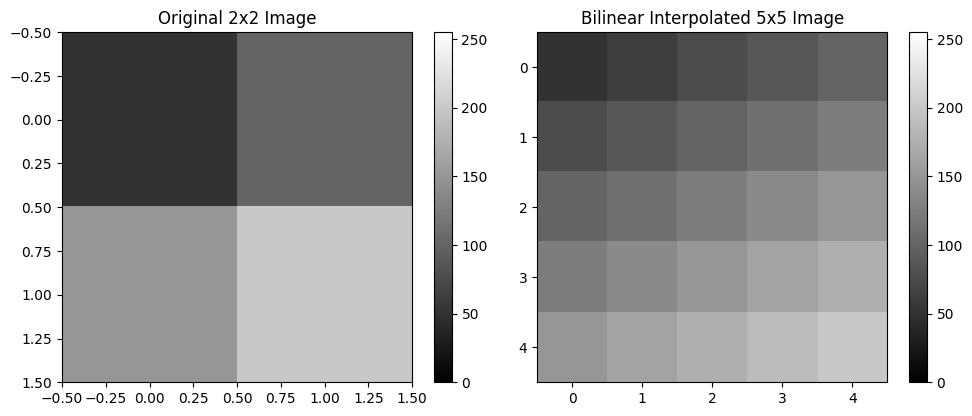

In [6]:
plt.figure(figsize=(10, 4))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original 2x2 Image")
plt.colorbar()

# Interpolated image
plt.subplot(1, 2, 2)
plt.imshow(output, cmap='gray', vmin=0, vmax=255)
plt.title("Bilinear Interpolated 5x5 Image")
plt.colorbar()

plt.tight_layout()
plt.show()